# 16 · What survives independent patch encoding?

Encode each oriented tile in isolation using frozen ResNet-50. Check the geometry before comparing observables. This design retains the known tile boundary and allows a clean test of what any permutation-invariant pooling must discard.

The patch mean, Q and pair profiles tie exactly on the clean pair. The triplet statistic separates it. Ridges and bars preserve the reference orientation signs while retaining just 2.4% and 3.5% of the clean third-order contrast.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.patterns import homometric
from observables.stage3 import FAMILIES, CONDITIONS, tile_library, cyclic_statistics
from observables.stage4 import Encoder, reference_images, mean_q_distance, patch_projection, unit
OUT = ROOT/'results'/'stage4'
OUT.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

## Preprocessing and polarity
Map signed intensities to grayscale around 0.5 using a fixed gain. Clip to [0,1], resize each tile to 32 × 32, replicate into three channels by broadcasting, and apply the checkpoint's channel means and standard deviations. These controlled inputs use a custom spatial preprocessing pipeline. The model runs in evaluation mode. We extract the unit vector at the final pooled layer, before the classification head.

For the sign-symmetric variant, encode the tile and its contrast-reversed copy separately, add their unit embeddings, and renormalize. This is an explicit representation design. It guarantees invariance to tile sign and is used throughout the retrieval benchmark.

,motif,orientation · plain,polarity · plain,orientation · symmetrized,polarity · symmetrized
0,windowed wave,0.155504,0.047470,0.141746,0.0
1,ridge,0.089369,0.399697,0.050113,-0.0
2,bar,0.104837,0.373452,0.057618,0.0


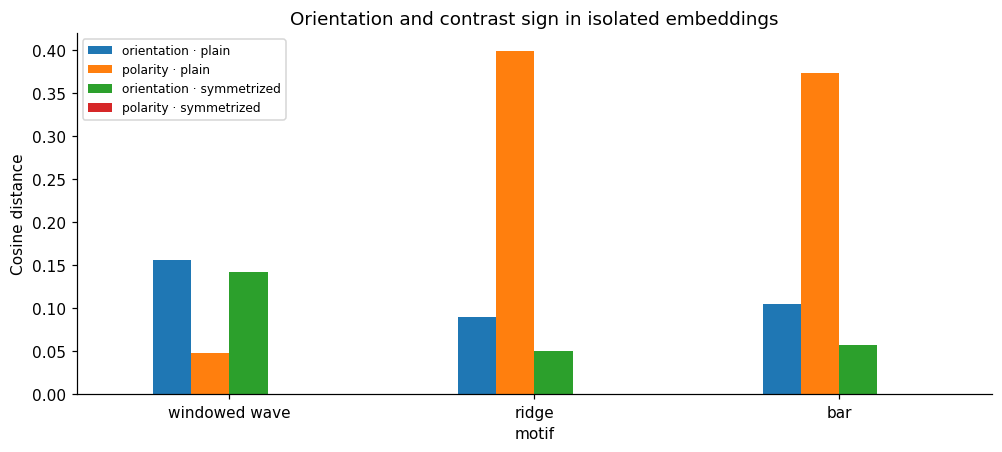

In [3]:
encoder=Encoder()
rows=[]
for family in FAMILIES:
    motifs=tile_library(family)
    plain=encoder.patch_embeddings(np.concatenate([motifs,-motifs]),symmetrize=False)
    sym=encoder.patch_embeddings(motifs)
    reverse=encoder.patch_embeddings(-motifs)
    np.testing.assert_allclose(sym,reverse,atol=1e-7)
    rows.append((family,1-plain[0]@plain[1],1-plain[0]@plain[2],
                 1-sym[0]@sym[1],1-sym[0]@reverse[0]))
dist=pd.DataFrame(rows,columns=['motif','orientation · plain','polarity · plain',
                              'orientation · symmetrized','polarity · symmetrized'])
display(dist.round(6));dist.to_csv(OUT/'patch_geometry.csv',index=False)
ax=dist.set_index('motif').plot.bar(figsize=(9,4),rot=0)
ax.set(ylabel='Cosine distance',title='Orientation and contrast sign in isolated embeddings')
ax.legend(fontsize=8);show('16_patch_geometry')

## Exact limits of global pooling
The encoded multisets of both arrangements are identical. Their vector means and Q-tensors therefore agree regardless of the encoder. We evaluate the Q distance using Gram matrices, with no explicit 2048 × 2048 tensor. For two unit-vector collections, the squared distance is $E[(u^Tu')^2]+E[(v^Tv')^2]-2E[(u^Tv)^2]$. The same isotropic subtraction cancels on both sides.

To compare spatial correlations, project each descriptor onto the difference of the two clean wave reference embeddings, centered and rescaled so those two references map to −1 and +1. This fixes the projection using gallery information alone.

In [5]:
reference=encoder.patch_embeddings(tile_library('windowed wave'))
za,zb=[reference[x.astype(int)] for x in homometric()]
pa,ta=cyclic_statistics(patch_projection(za,reference))
pb,tb=cyclic_statistics(patch_projection(zb,reference))
assert np.linalg.norm(za.mean(0)-zb.mean(0))<1e-12
assert mean_q_distance(za,zb)<1e-7
np.testing.assert_allclose(pa,pb,atol=1e-12)
print('Mean distance:',np.linalg.norm(za.mean(0)-zb.mean(0)))
print('Q distance:',mean_q_distance(za,zb))
print('Max pair difference:',np.max(np.abs(pa-pb)))
print('Triplet at (1,4):',ta[1,4],tb[1,4])
assert np.allclose([ta[1,4],tb[1,4]],[2/3,0],atol=1e-12)

Mean distance: 6.247265799728688e-17
Q distance: 0.0
Max pair difference: 7.401486830834377e-17
Triplet at (1,4): 0.6666666666666669 -4.108650548026103e-33


## Does the wave axis transfer?
The next table measures where the two new motif families land on the reference axis. Values retain their sign and magnitude, and they may fall outside [−1,1]. The gallery mapping cannot guarantee the sign of a new motif.

In [7]:
axis=pd.DataFrame([patch_projection(encoder.patch_embeddings(tile_library(f)),reference) for f in FAMILIES],
                  index=FAMILIES,columns=['motif 0','motif 1'])
display(axis.round(4));axis.to_csv(OUT/'reference_axis_transfer.csv')

,motif 0,motif 1
windowed wave,-1.0000,1.0000
ridge,-0.3481,0.2265
bar,-0.4174,0.2347


## An exact transfer prediction
If the two clean transferred motifs project to p₀ and p₁, then their sequence is $p=\beta+\gamma s$, where $s=2x-1$ and $\gamma=(p_1-p_0)/2$. Expand the triple product. The constant, linear and quadratic terms cancel between the homometric arrangements because their one- and two-point statistics agree. The difference of their triplet arrays is therefore exactly $\gamma^3(T_A-T_B)$. This predicts the loss of absolute triplet contrast in clean transfer before adding noise or choosing a distance rule.

In [9]:
gain=(axis['motif 1']-axis['motif 0'])/2
contrast=pd.DataFrame({'orientation gain':gain,'relative clean triplet contrast':gain**3})
for family in FAMILIES:
    p=axis.loc[family].to_numpy()
    actual=[cyclic_statistics(p[x.astype(int)])[1] for x in homometric()]
    np.testing.assert_allclose(actual[0]-actual[1],gain[family]**3*(ta-tb),atol=1e-12)
display(contrast.round(5))
contrast.to_csv(OUT/'triplet_transfer_gain.csv')

,orientation gain,relative clean triplet contrast
windowed wave,1.00000,1.00000
ridge,0.28729,0.02371
bar,0.32606,0.03466
